# FraudScope: from transaction to review decision

An executed end-to-end reference prepared for Sileshi Hirpa. All data in this notebook is synthetic. No IEEE-CIS score or production approval is claimed. Read `docs/START_HERE.md` alongside the code.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from fraudscope.synthetic import generate
from fraudscope.features import build_features
from fraudscope.contracts import NUMERIC, CATEGORICAL
from fraudscope.splits import temporal_split
from fraudscope.pipeline import run_experiment
from fraudscope.models import load_bundle
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Run from the project root or notebooks folder"

## 1. Simulate a population

Hidden attack intent creates overlapping signals. Outcomes are stochastic. Repeated accounts, shared devices, a changed final-period population and delayed labels let us test more than a static classifier.

In [2]:
df = generate(n=60000, seed=42)
display(df[["transaction_id", "event_time", "amount", "channel", "is_fraud"]].head())
display(pd.DataFrame({"rows": [len(df)], "fraud_rate": [df.is_fraud.mean()], "days": [(df.event_time.max()-df.event_time.min())/86400]}))

,transaction_id,event_time,amount,channel,is_fraud
0,s42_00000000,136.531591,66.15,app,0
1,s42_00000001,199.475308,88.08,app,0
2,s42_00000002,284.755395,29.34,app,0
3,s42_00000003,489.471509,5.44,app,0
4,s42_00000004,524.901020,2.66,web,0


,rows,fraud_rate,days
0,60000,0.060867,119.997668


## 2. Check data and reveal the simulator

The audit-only scenario is useful for understanding how the simulator behaves. It must never enter the model.

,events,fraud_rate,mean_amount
scenario_audit_only,,,
account_takeover,2326,0.730009,125.415348
card_testing,1188,0.708754,7.589024
ordinary,55096,0.002360,64.865791
social_engineering,1390,0.706475,123.726424


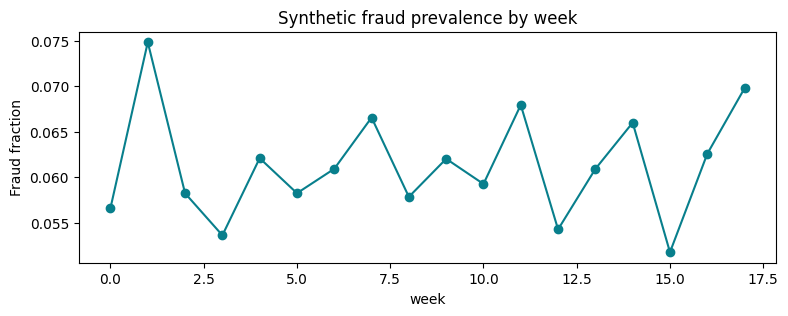

In [3]:
assert df.transaction_id.is_unique
assert df.event_time.is_monotonic_increasing
assert (df.label_available_time > df.event_time).all()
display(df.groupby("scenario_audit_only").agg(events=("is_fraud","size"), fraud_rate=("is_fraud","mean"), mean_amount=("amount","mean")))
weekly = df.assign(week=(df.event_time/604800).astype(int)).groupby("week").is_fraud.mean()
weekly.plot(figsize=(9,3), marker="o", color="#087f8c", title="Synthetic fraud prevalence by week", ylabel="Fraud fraction")
plt.show()

## 3. Build point-in-time features

A transaction can use earlier activity, including earlier unlabeled events. It cannot use later transactions or outcome labels. The same `extract` function is used by the API.

In [4]:
X = build_features(df)
assert set(X.columns) == set(NUMERIC + CATEGORICAL)
assert "is_fraud" not in X and "scenario_audit_only" not in X
display(X.head())
original_prefix = build_features(df.iloc[:500])
changed = df.iloc[:1000].copy()
changed.loc[500:, "amount"] = 9999
pd.testing.assert_frame_equal(original_prefix, build_features(changed).iloc[:500])
print("Future-amount perturbation did not change earlier features.")

Future-amount perturbation did not change earlier features.


,log_amount,account_age_days,email_age_days,geo_distance_km,failed_logins_24h,cross_border,hour_sin,hour_cos,account_txn_1h,account_txn_24h,amount_ratio_7d,device_accounts_24h,new_device_7d,account_txn_7d,channel,product,device_type
0,4.206929,198.346916,206.180064,17.362464,0,0,0.009929,0.999951,0,0,1.0,0,1,0,app,digital,mobile
1,4.489535,272.016234,161.299721,11.635847,2,0,0.014506,0.999895,0,0,1.0,0,1,0,app,digital,desktop
2,3.412467,575.667891,396.407222,11.254254,1,0,0.020707,0.999786,0,0,1.0,0,1,0,app,retail,tablet
3,1.862529,811.129058,596.176579,75.095232,0,0,0.035588,0.999367,0,0,1.0,0,1,0,app,digital,mobile
4,1.297463,302.381849,204.190757,13.681195,0,0,0.038163,0.999272,0,0,1.0,0,1,0,web,travel,mobile


## 4. Separate training, calibration, policy selection and test

Chronological boundaries are measured in elapsed time. Training outcomes must mature before calibration starts. Calibration outcomes must mature before validation starts. Validation outcomes must mature before the test starts.

In [5]:
idx, split = temporal_split(df)
rows=[]
for stage, ix in idx.items():
    rows.append({"stage":stage,"n":len(ix),"first_day":df.iloc[ix].event_time.min()/86400,"last_day":df.iloc[ix].event_time.max()/86400,"fraud_rate":df.iloc[ix].is_fraud.mean()})
display(pd.DataFrame(rows))
print("Supervised rows excluded for label maturity:", split["purged_rows"])

Supervised rows excluded for label maturity: 3014


,stage,n,first_day,last_day,fraud_rate
0,train,31916,0.001580,63.999727,0.060941
1,calibration,8015,66.000636,81.999600,0.062757
2,validation,5110,84.001218,93.999607,0.055382
3,test,11945,96.001805,119.999248,0.061365


## 5. Train, calibrate and freeze the operating policy

This cell runs the experiment, including the three model families. It selects a supervised model by minimum validation estimated cost subject to a 5% review target, before evaluating the final test. Isolation Forest is an anomaly challenger. Isotonic calibration is fitted on a separate period.

In [6]:
result = run_experiment(df, X, NUMERIC, CATEGORICAL, ROOT / "reports/notebook_run", seed=42)
display(pd.DataFrame([{ "model":r["model"], "validation_raw_AP":r["validation_raw_ap"], "test_raw_AP":r["test_raw_ap"], "reported_test_AP":r["test"]["average_precision"], "test_ROC_AUC":r["test"]["roc_auc"] } for r in result["models"]]))
print("Selected model:", result["winner"])
print("Frozen threshold:", result["policy"]["threshold"])

Selected model: logistic
Frozen threshold: 0.5111111111111111


,model,validation_raw_AP,test_raw_AP,reported_test_AP,test_ROC_AUC
0,logistic,0.438068,0.478930,0.455098,0.826901
1,hist_gradient_boosting,0.503293,0.493587,0.479258,0.863466
2,isolation_forest,0.318966,0.335308,0.335308,0.796493


## 6. Inspect ranking, calibration and drift

Average precision summarizes the precision-recall curve using recall increments. It differs from trapezoidal PR area. The top-5% metrics are retrospective ranking measures. A fixed threshold is a separate policy that can yield a different review count.

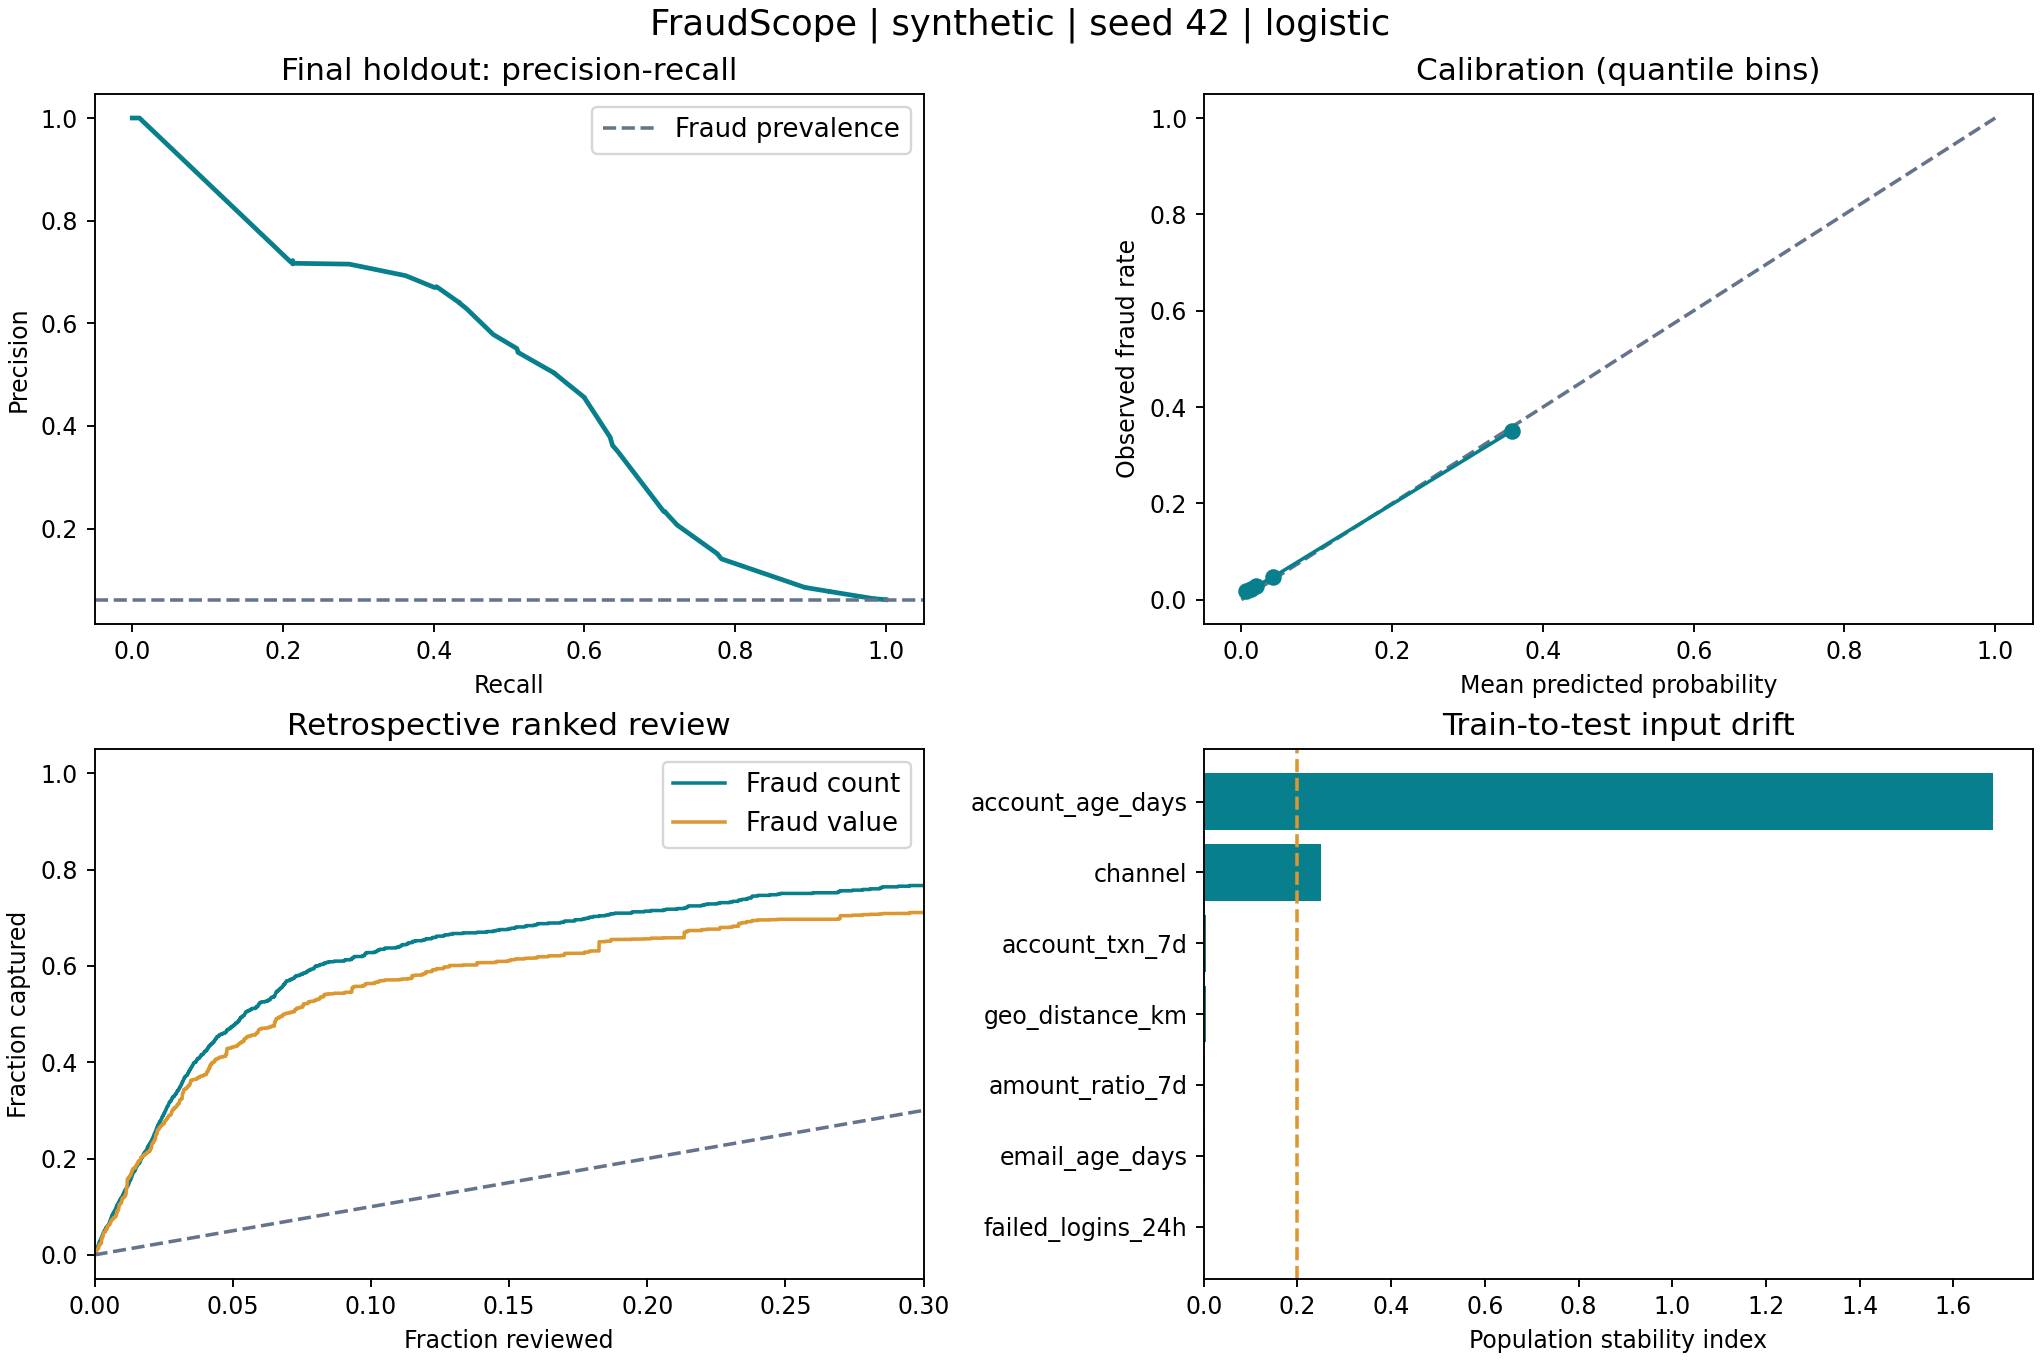

n                           11945
fraud_count                   733
fraud_rate               0.061365
average_precision        0.455098
roc_auc                  0.826901
recall_at_5pct           0.474761
precision_at_5pct        0.582915
value_capture_at_5pct     0.43123
brier                    0.040728
log_loss                 0.164966
review_rate              0.041356
review_count                  494
true_reviews                  317
false_reviews                 177
policy_precision           0.6417
policy_recall            0.432469
false_positive_rate      0.015787
estimated_cost           55805.68
no_review_cost           77402.04
estimated_savings        21596.36
capacity_exceeded           False
Name: Final test, dtype: object

low             0.420859
high            0.493006
replicates    300.000000
Name: AP day-bootstrap interval, dtype: float64

In [7]:
display(Image(filename=str(ROOT / "reports/notebook_run/evaluation.png")))
display(pd.Series(result["test"], name="Final test"))
display(pd.Series(result["average_precision_day_bootstrap_95pct"], name="AP day-bootstrap interval"))

## 7. Connect the policy to cost

The illustrative cost is $C=\sum_i[y_i a_i(1-\rho r_i)+c_r r_i+c_f(1-y_i)r_i]$. Here review costs $3, legitimate-review friction costs an additional $5, and 80% of fraud value is assumed recoverable after review. These are assumptions, not realized savings. We keep the policy frozen while varying cost assumptions.

In [8]:
display(pd.read_csv(ROOT / "reports/notebook_run/cost_sensitivity.csv"))
policy=result["policy"]
t=result["test"]
print(f"Reviews: {t["review_count"]:,}; true fraud reviews: {t["true_reviews"]:,}; false reviews: {t["false_reviews"]:,}")

Reviews: 494; true fraud reviews: 317; false reviews: 177


,review_fee,recovery_fraction,fixed_threshold,estimated_cost,estimated_avoided_cost
0,1.0,0.3,0.511111,69794.78,7607.26
1,1.0,0.5,0.511111,63803.94,13598.10
2,1.0,0.8,0.511111,54817.68,22584.36
3,3.0,0.3,0.511111,70782.78,6619.26
4,3.0,0.5,0.511111,64791.94,12610.10
5,3.0,0.8,0.511111,55805.68,21596.36
6,10.0,0.3,0.511111,74240.78,3161.26
7,10.0,0.5,0.511111,68249.94,9152.10
8,10.0,0.8,0.511111,59263.68,18138.36


## 8. Explain without inventing a story

Permutation importance measures validation AP changes after shuffling a feature. It can understate correlated features. Case evidence records observations and policy references. Reference-replacement sensitivity is not SHAP, a causal effect, or an additive decomposition.

In [9]:
display(pd.DataFrame(result["importance"]).head(10))
cases=json.loads((ROOT / "reports/notebook_run/cases.json").read_text())
display(pd.DataFrame(cases[0]["brief"]["evidence"]))
display(pd.DataFrame(cases[0]["reference_sensitivity"]))
print(cases[0]["brief"]["caveat"])

Evidence rules are observations, not model attributions or proof of fraud.


,feature,ap_drop_mean,ap_drop_std
0,account_txn_1h,0.270562,0.001131
1,failed_logins_24h,0.119710,0.002955
2,device_accounts_24h,0.079084,0.001109
3,email_age_days,0.068823,0.008834
4,account_age_days,0.056653,0.003351
5,new_device_7d,0.040838,0.005659
6,account_txn_7d,0.027111,0.001144
7,geo_distance_km,0.020519,0.005379
8,account_txn_24h,0.004983,0.002733
9,product,0.002203,0.000694


,feature,observed,statement
0,account_txn_1h,5.000000,Multiple earlier transactions within one hour
1,failed_logins_24h,4.000000,Several recent failed sign-ins
2,geo_distance_km,7526.629189,Large distance from the supplied reference loc...


,feature,score_change,reference
0,failed_logins_24h,0.215311,0.000000
1,account_txn_1h,0.215311,0.000000
2,geo_distance_km,0.181818,23.477567
3,device_accounts_24h,0.181818,0.000000
4,account_txn_7d,0.181818,1.000000
5,cross_border,0.044969,0.000000


## 9. Check the saved artifact and simulation stability

The artifact loader checks its digest and scikit-learn version. Only load trusted local artifacts because joblib can execute code. Seed variability describes independent simulated populations, not uncertainty about real deployment.

In [10]:
bundle=load_bundle(ROOT / "reports/notebook_run/model.joblib")
computed=bundle.predict(X.iloc[idx["test"]])
saved=pd.read_csv(ROOT / "reports/notebook_run/holdout_predictions.csv")
assert np.allclose(computed, saved.score)
summary=json.loads((ROOT / "reports/demo/multi_seed_summary.json").read_text())
display(pd.DataFrame(summary["runs"])[["seed","winner","average_precision","roc_auc","recall_at_5pct","review_rate","capacity_exceeded"]])
print("Reloaded predictions match the stored test predictions.")

Reloaded predictions match the stored test predictions.


,seed,winner,average_precision,roc_auc,recall_at_5pct,review_rate,capacity_exceeded
0,42,logistic,0.455098,0.826901,0.474761,0.041356,False
1,73,hist_gradient_boosting,0.465844,0.838660,0.515670,0.038759,False
2,101,hist_gradient_boosting,0.511267,0.853777,0.498750,0.051271,True


## 10. Operational extension

Run the API and `scripts/replay.py` using the README. The test suite verifies offline/online parity, idempotency, ordering, model integrity, audit modifications and delayed-label filtering. Monitoring never retrains automatically.

## 11. Real IEEE-CIS benchmark

Real data is not bundled and real metrics are pending. Place authorized files in `data/ieee` and run:

```bash
python -m fraudscope.cli benchmark --data data/ieee --out reports/ieee --label-lag-days 2
```

Read `docs/IEEE_BENCHMARK.md` before comparing results. The two-day delay is an assumption. No competition test labels are invented. A local temporal score is not a leaderboard result.

## 12. Your independent investigation

Predeclare one improvement, such as expected-loss ranking, temporal graph ablation or a realistic label-delay study. Use a fresh final period. Record results, limitations and your own contribution before presenting the project. See `docs/PORTFOLIO_STORY.md`.